# Modelado · Clasificación de diabetes (cribado)
### Proyecto de Aprendizaje Automático · Punto de control 2

**Objetivo.** Predecir `diabetes` a partir de la encuesta, como herramienta de **cribado**: ordenar a los pacientes por riesgo para decidir a quién citar a una prueba diagnóstica. El modelo resultante es el que sirve la API común (`src/servicio.py`).

**Resumen ejecutivo**

| | Resultado |
|---|---|
| **Modelo final** | Ensamble por voto suave: regresión logística con *splines* + *gradient boosting* poco profundo. Ambos están hiperparametrizados. |
| **Entrada** | 18 columnas **crudas** del CSV. Limpieza, imputación y escalado van dentro del pipeline. |
| **Test (n = 2 550, IC 95 %)** | **ROC-AUC 0,826** [0,809–0,842] · PR-AUC 0,683 · Brier 0,158 |
| **Decisión con umbral 0,35** | Sensibilidad **0,76** · especificidad 0,73 · VPP 0,58. Detecta 644 de los 848 diabéticos de test. |
| **Generalización** | Test ≈ CV (0,826 frente a 0,828) y probabilidades bien calibradas, sin necesidad de recalibrar. |

**Decisiones clave**
1. **Ninguna línea usa como predictor el objetivo de la otra** (revisión pedida en el PC1). `dias_salud_fisica_mala` no aporta nada a la clasificación (ΔROC-AUC = 0,000), ni `diabetes` a la regresión (ΔMAE = −0,002 días). Exigirlos en la API solo añadiría riesgo de fallo.
2. **La complejidad aporta poco, pero de forma consistente.** Todas las familias razonables rinden entre 0,816 y 0,827. El ensamble supera a la logística simple en **24 de 25** particiones de una CV repetida (+0,004 de AUC). La mejora es pequeña pero sistemática.
3. **Umbral 0,35 en lugar de 0,5.** Captura 20 puntos más de diabéticos (sensibilidad de 0,58 a 0,77) a cambio de 13 puntos de especificidad, el intercambio adecuado para un cribado.
4. **Lo que el modelo usa**: salud percibida, IMC, edad, hipertensión y colesterol, en ese orden, con efectos monótonos y clínicamente plausibles. Coincide con el EDA.

**Índice**
1. Datos y protocolo de evaluación
2. ¿Objetivo de la otra línea como predictor?
3. Métricas
4. Comparación de familias
5. Hiperparametrización
6. Elección final
7. Calibración y umbral
8. Evaluación en test
9. Interpretación
10. Descartes y limitaciones
11. Comprobaciones finales
12. Artefacto y API

Figuras: `reports/figures/fig21`–`fig28`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline

# `src/` va en sys.path igual que en el servicio: así el modelo referencia
# `preprocesamiento.*` y `modelado.*`, que la API resuelve desde cualquier directorio.
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import eda_utils as eu
import modelado as md
import preprocesamiento as pp

warnings.filterwarnings("ignore", message=".*valores no reconocidos.*")
eu.configurar_estilo()
LINEA = "clasificacion"

## 1. Datos y protocolo de evaluación

- **Misma partición que en el punto de control 1** (`pp.dividir`, 80/20 estratificada, semilla 42): 10 200 pacientes para desarrollar y 2 550 de test.
- **Entrada del modelo = columnas crudas mínimas** (`pp.columnas_crudas`): 18 columnas tal y como vienen en el CSV. Nada de PII, id, `usuario_alta_datos` ni el otro objetivo (sección 2). El modelo es un único `Pipeline` (limpieza → derivadas → imputación/escalado → estimador), así que lo que se valida aquí es exactamente lo que servirá la API.
- **Toda la selección (familias, hiperparámetros, calibración y umbral) se hace con validación cruzada estratificada de 5 pliegues dentro de train**, con los mismos pliegues para todos los modelos para poder comparar de forma pareada. **El test se usa una sola vez**, en la sección 8.

In [2]:
crudo = pp.cargar_datos()
X_train_todo, X_test_todo, y_train, y_test = pp.dividir(crudo, LINEA)
COLUMNAS = pp.columnas_crudas(LINEA)
X_train, X_test = X_train_todo[COLUMNAS], X_test_todo[COLUMNAS]

pd.DataFrame({
    "pacientes": [len(y_train), len(y_test)],
    "% diabetes": [y_train.mean(), y_test.mean()],
    "columnas de entrada": [X_train.shape[1], X_test.shape[1]],
}, index=["train", "test"]).style.format({"% diabetes": "{:.1%}"})

,pacientes,% diabetes,columnas de entrada
train,10200,33.2%,18
test,2550,33.3%,18


In [3]:
print("Columnas que pide el modelo:", COLUMNAS)
assert not set(COLUMNAS) & set(pp.COLS_PII + pp.COLS_GESTION + [pp.COL_ID, pp.TARGET_CLASIF, pp.TARGET_REGR])

Columnas que pide el modelo: ['imc', 'dias_salud_mental_mala', 'grupo_edad', 'salud_general', 'nivel_educativo', 'nivel_ingresos', 'presion_alta', 'colesterol_alto', 'chequeo_colesterol_5a', 'fumador', 'ictus', 'enfermedad_cardiaca', 'actividad_fisica', 'consume_fruta', 'consume_verdura', 'consumo_alcohol_alto', 'dificultad_caminar', 'sexo']


## 2. ¿Tiene sentido usar el objetivo de la otra línea como predictor?

Revisión pedida en el punto de control 1. En el PC1 `dias_salud_fisica_mala` entraba como predictor de `diabetes`, y `diabetes` como predictor de `dias_salud_fisica_mala`. Hay dos argumentos para revisarlo:

1. **De dominio.** El objetivo de la clasificación es *cribar* a quién citar para una prueba diagnóstica. En ese uso, que el paciente tenga diabetes es justo lo que se desconoce, y el "otro" objetivo es una respuesta de la misma encuesta, sin garantía de estar disponible cuando se pide la predicción.
2. **De servicio.** El servicio responde con 422 si falta cualquier columna que el modelo use. Si el profesor envía las instancias de una línea sin el objetivo de la otra, la línea entera se queda sin evaluar en la fase competitiva.

Así que solo merecería la pena mantenerlos si aportaran una mejora clara. Se mide con dos modelos por línea, con y sin el objetivo cruzado, sobre los **mismos pliegues** (diferencias pareadas). En regresión la métrica es el MAE, la que el EDA recomendó para un objetivo cero-inflado.

In [4]:
def comparar_objetivo_cruzado(linea, estimadores, scoring, signo):
    X_tr, _, y_tr, _ = pp.dividir(crudo, linea)
    estratos = y_tr if linea == "clasificacion" else pp.tramos_regresion(y_tr)
    pliegues = list(StratifiedKFold(md.N_PLIEGUES, shuffle=True, random_state=pp.SEMILLA).split(X_tr, estratos))
    filas = []
    for nombre, est in estimadores.items():
        punt = {}
        for cruzado in (False, True):
            modelo = Pipeline([("pre", pp.construir_preprocesador(linea, cruzado)), ("modelo", est)])
            cols = pp.columnas_crudas(linea, cruzado)
            punt[cruzado] = signo * cross_validate(modelo, X_tr[cols], y_tr, cv=pliegues, scoring=scoring, n_jobs=-1)["test_score"]
        mejora = (punt[True] - punt[False]) * (1 if scoring == "roc_auc" else -1)
        filas.append({"línea": linea, "modelo": nombre, "sin": punt[False].mean(), "con": punt[True].mean(),
                      "mejora media": mejora.mean(), "de mejora": mejora.std(),
                      "pliegues en que mejora": f"{(mejora > 0).sum()}/{len(mejora)}"})
    return filas

filas = comparar_objetivo_cruzado(
    "clasificacion", {"Logística": md.logistica(), "Gradient Boosting": md.gradient_boosting()}, "roc_auc", 1)
filas += comparar_objetivo_cruzado(
    "regresion",
    {"GLM Poisson": PoissonRegressor(alpha=1e-3, max_iter=2000),
     "HGB (pérdida Poisson)": HistGradientBoostingRegressor(loss="poisson", max_leaf_nodes=8, learning_rate=0.05,
                                                            max_iter=300, random_state=pp.SEMILLA)},
    "neg_mean_absolute_error", -1)
objetivo_cruzado = pd.DataFrame(filas).set_index(["línea", "modelo"])
objetivo_cruzado.columns = ["sin objetivo cruzado", "con objetivo cruzado", "mejora media", "de mejora", "pliegues en que mejora"]
objetivo_cruzado.style.format(precision=4).set_caption(
    "Clasificación: ROC-AUC (más es mejor) · Regresión: MAE en días (menos es mejor). Mejora > 0 = a favor de incluirlo")

**Hallazgo.** En las dos líneas y con los dos modelos, la diferencia es nula, del orden de la diezmilésima y por debajo de su propia variabilidad entre pliegues. En clasificación, añadir `dias_salud_fisica_mala` cambia el ROC-AUC en +0,0000 (logística) y −0,0005 (boosting). En regresión, añadir `diabetes` *empeora* el MAE en 0,001–0,002 días. Lo que estas variables aportan ya lo recogen otras (sobre todo `salud_general` y `dificultad_caminar`, muy asociadas a ambas en el EDA).

**Decisión: se descartan en ambas líneas.** `pp.columnas_features` ya no los incluye, y queda el parámetro `con_objetivo_cruzado=True` solo para reproducir esta prueba. Con esto la API de clasificación no exige `dias_salud_fisica_mala`, ni la de regresión `diabetes`. La línea de clusterización sí los conserva: describen el perfil de salud y ahí no hay nada que predecir.

## 3. Métricas: qué se optimiza y por qué

| Uso | Métrica | Por qué |
|---|---|---|
| **Selección de modelo** | **ROC-AUC** | Un cribado *ordena* pacientes para decidir a quién citar primero. El AUC mide justo eso, la capacidad de ranking, sin depender del umbral ni de la prevalencia artificial del 33 %. |
| Apoyo | PR-AUC | Más sensible al rendimiento en la clase positiva. Su referencia es la prevalencia (0,33), no 0,5. |
| **Calidad de la probabilidad** | **Brier** y **log-loss** | El contrato devuelve una `probabilidad`, que debe ser fiable y no solo ordenar bien. |
| Decisión (`clase`) | Sensibilidad, especificidad, VPP, F1 | Dependen del umbral (sección 7). En cribado se prioriza no dejar diabéticos sin citar. |

Ningún modelo se elige por exactitud: con un 67 % de negativos, decir siempre "no" ya da un 67 %.

## 4. Primera ronda: comparación de familias

Siete modelos con hiperparámetros razonables por defecto (`md.candidatos`), de menos a más complejos:

- **Referencias.**
  - `Dummy`: predice siempre la prevalencia; es el suelo.
  - Logística con solo 4 indicadores clínicos (presión, colesterol, IMC, edad): lo que haría un médico "a ojo".
- **Lineales.**
  - Logística sobre todas las variables.
  - Logística con *splines*, que permite efectos no lineales del IMC, la edad o la salud percibida sin dejar de ser aditiva e interpretable.
- **No lineales.**
  - KNN.
  - Random Forest.
  - Gradient Boosting (`HistGradientBoosting`), que capta interacciones.

In [5]:
cv = md.validacion_cruzada()
resultados_cv = {nombre: md.evaluar_cv(md.construir_modelo(LINEA, est), X_train, y_train, cv)
                 for nombre, est in md.candidatos().items()}

def resumir(resultados):
    tabla = pd.DataFrame({n: r.mean() for n, r in resultados.items()}).T
    de = pd.DataFrame({n: r.std() for n, r in resultados.items()}).T
    salida = tabla.copy().astype(object)
    for col in ["ROC-AUC", "PR-AUC", "Brier", "Log-loss"]:
        salida[col] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(tabla[col], de[col])]
    salida["Tiempo ajuste (s)"] = tabla["Tiempo ajuste (s)"].round(2)
    return tabla, salida

tabla_familias, vista = resumir(resultados_cv)
vista.loc[tabla_familias["ROC-AUC"].sort_values(ascending=False).index]

,ROC-AUC,PR-AUC,Brier,Log-loss,Tiempo ajuste (s)
Logística + splines,0.8251 ± 0.0149,0.6764 ± 0.0299,0.1582 ± 0.0065,0.4766 ± 0.0160,0.120
Gradient Boosting,0.8247 ± 0.0154,0.6745 ± 0.0301,0.1586 ± 0.0072,0.4763 ± 0.0191,0.390
Logística,0.8230 ± 0.0156,0.6670 ± 0.0251,0.1598 ± 0.0070,0.4817 ± 0.0174,0.120
Random Forest,0.8200 ± 0.0132,0.6705 ± 0.0282,0.1604 ± 0.0057,0.4817 ± 0.0134,1.090
KNN (k=50),0.8155 ± 0.0150,0.6564 ± 0.0330,0.1623 ± 0.0062,0.5049 ± 0.0307,0.090
Logística clínica (4 var.),0.7800 ± 0.0120,0.6072 ± 0.0223,0.1756 ± 0.0045,0.5242 ± 0.0114,0.100
Dummy (prevalencia),0.5000 ± 0.0000,0.3324 ± 0.0000,0.2219 ± 0.0000,0.6358 ± 0.0000,0.090


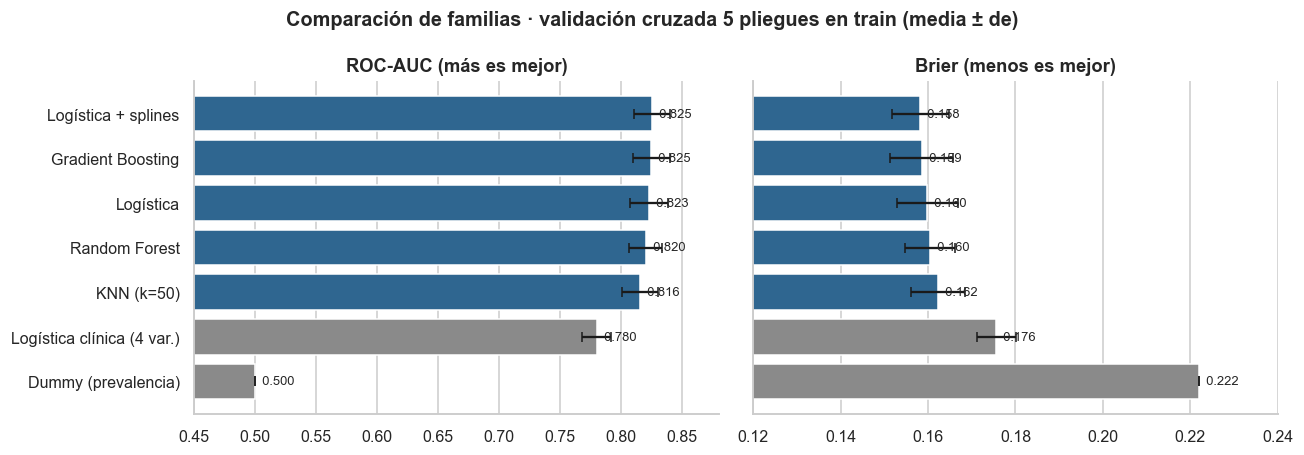

In [6]:
orden = tabla_familias["ROC-AUC"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, metrica, titulo in [(axes[0], "ROC-AUC", "ROC-AUC (más es mejor)"), (axes[1], "Brier", "Brier (menos es mejor)")]:
    medias = [resultados_cv[n][metrica].mean() for n in orden]
    des = [resultados_cv[n][metrica].std() for n in orden]
    colores = [eu.GRIS if "Dummy" in n or "clínica" in n else eu.AZUL for n in orden]
    ax.barh(orden, medias, xerr=des, color=colores, capsize=3)
    ax.set_title(titulo)
    eu.rejilla_x(ax)
    for i, m in enumerate(medias):
        ax.text(m, i, f"  {m:.3f}", va="center", fontsize=8.5)
axes[0].set_xlim(0.45, 0.88)
axes[1].set_xlim(0.12, 0.24)
fig.suptitle("Comparación de familias · validación cruzada 5 pliegues en train (media ± de)")
fig.tight_layout()
eu.guardar_figura(fig, "fig21_comparativa_modelos")

In [7]:
# Diferencias pareadas frente a la logística simple (mismos pliegues)
ref = resultados_cv["Logística"]["ROC-AUC"]
pd.DataFrame({
    n: {"ΔROC-AUC medio": (r["ROC-AUC"] - ref).mean(), "pliegues mejor que la logística": f"{((r['ROC-AUC'] - ref) > 0).sum()}/5"}
    for n, r in resultados_cv.items() if n != "Logística"
}).T

,ΔROC-AUC medio,pliegues mejor que la logística
Dummy (prevalencia),-0.323,0/5
Logística clínica (4 var.),-0.043,0/5
Logística + splines,0.002,5/5
KNN (k=50),-0.007,0/5
Random Forest,-0.003,1/5
Gradient Boosting,0.002,4/5


**Hallazgos.** - **Todo modelo razonable queda en ROC-AUC 0,816–0,825.** La distancia entre los cuatro primeros (≈ 0,005) es menor que la desviación entre pliegues (≈ 0,015). La señal es mayoritariamente **aditiva y monótona**, como ya anticipaba el EDA.
- Los **4 indicadores clínicos solos** dan 0,780. El resto de la encuesta (sobre todo la salud percibida) suma +0,045 de AUC.
- La **logística con splines** y el **boosting** son los únicos que superan a la logística simple de forma consistente (5/5 y 4/5 pliegues). KNN y Random Forest quedan por debajo y son más lentos: se descartan.

## 5. Hiperparametrización de las dos mejores familias

- **Logística con splines**: búsqueda en rejilla sobre la regularización `C` y el número de nodos del spline del IMC y del resto de variables (36 combinaciones). La rejilla es exhaustiva porque el modelo es barato.
- **Gradient Boosting**: búsqueda aleatoria de 40 combinaciones sobre la tasa de aprendizaje, el tamaño de los árboles, el mínimo de pacientes por hoja, la regularización L2 y el número de iteraciones. Con 5 hiperparámetros continuos, una rejilla sería inabarcable.

Ambas se puntúan con ROC-AUC en los mismos 5 pliegues.

In [8]:
busqueda_log = GridSearchCV(
    md.construir_modelo(LINEA, md.logistica_splines()),
    {"modelo__logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1, 3],
     "modelo__columntransformer__imc__n_knots": [4, 5, 7],
     "modelo__columntransformer__resto__n_knots": [4, 5]},
    scoring="roc_auc", cv=cv, n_jobs=-1,
).fit(X_train, y_train)

busqueda_gb = RandomizedSearchCV(
    md.construir_modelo(LINEA, md.gradient_boosting()),
    {"modelo__learning_rate": loguniform(0.01, 0.2), "modelo__max_leaf_nodes": randint(4, 32),
     "modelo__min_samples_leaf": randint(10, 200), "modelo__l2_regularization": loguniform(1e-3, 10),
     "modelo__max_iter": randint(100, 600)},
    n_iter=40, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=pp.SEMILLA,
).fit(X_train, y_train)

bp = busqueda_log.best_params_
params_log = {"C": bp["modelo__logisticregression__C"],
              "nodos_imc": bp["modelo__columntransformer__imc__n_knots"],
              "nodos_resto": bp["modelo__columntransformer__resto__n_knots"]}
# Se redondean ya aquí: estos valores son los que se usan en todo lo que sigue y en CONFIG_FINAL
params_gb = {k.removeprefix("modelo__"): (round(float(v), 4) if isinstance(v, float) else int(v))
             for k, v in busqueda_gb.best_params_.items()}

print(f"Logística + splines → {params_log} · ROC-AUC CV = {busqueda_log.best_score_:.4f}")
print(f"Gradient Boosting   → {params_gb} · ROC-AUC CV = {busqueda_gb.best_score_:.4f}")

Logística + splines → {'C': 1, 'nodos_imc': 4, 'nodos_resto': 4} · ROC-AUC CV = 0.8261
Gradient Boosting   → {'l2_regularization': 7.076, 'learning_rate': 0.0213, 'max_iter': 485, 'max_leaf_nodes': 6, 'min_samples_leaf': 122} · ROC-AUC CV = 0.8268


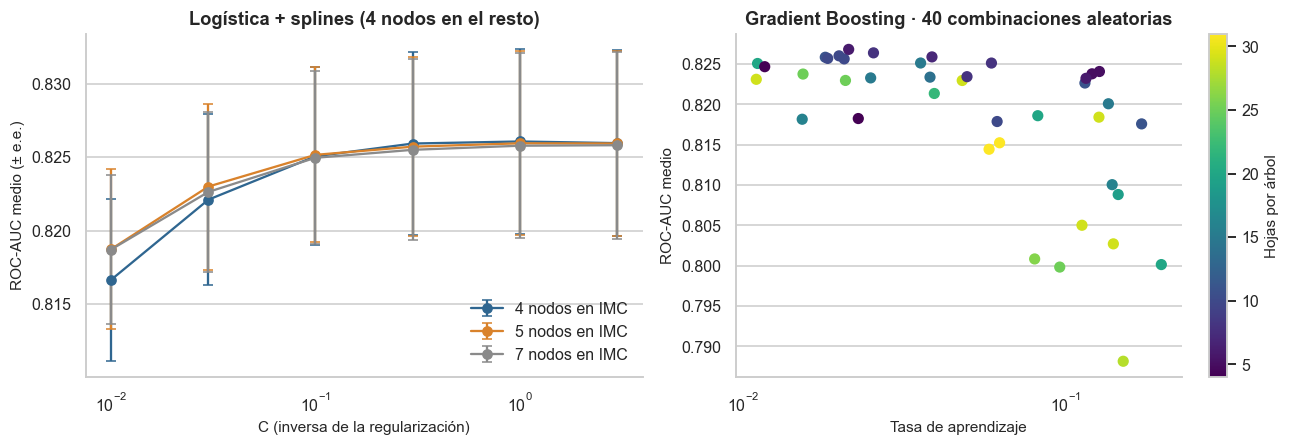

In [9]:
res_log = pd.DataFrame(busqueda_log.cv_results_)
res_gb = pd.DataFrame(busqueda_gb.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
mejor_resto = params_log["nodos_resto"]
for i, (nodos, grupo) in enumerate(res_log[res_log["param_modelo__columntransformer__resto__n_knots"] == mejor_resto]
                                   .groupby("param_modelo__columntransformer__imc__n_knots")):
    grupo = grupo.sort_values("param_modelo__logisticregression__C")
    ax.errorbar(grupo["param_modelo__logisticregression__C"].astype(float), grupo["mean_test_score"],
                yerr=grupo["std_test_score"] / np.sqrt(md.N_PLIEGUES), marker="o", capsize=3,
                label=f"{nodos} nodos en IMC", color=[eu.AZUL, eu.NARANJA, eu.GRIS][i])
ax.set_xscale("log")
ax.set(xlabel="C (inversa de la regularización)", ylabel="ROC-AUC medio (± e.e.)",
       title=f"Logística + splines ({mejor_resto} nodos en el resto)")
ax.legend()

ax = axes[1]
sc = ax.scatter(res_gb["param_modelo__learning_rate"].astype(float), res_gb["mean_test_score"],
                c=res_gb["param_modelo__max_leaf_nodes"].astype(int), cmap="viridis", s=40)
ax.set_xscale("log")
ax.set(xlabel="Tasa de aprendizaje", ylabel="ROC-AUC medio", title="Gradient Boosting · 40 combinaciones aleatorias")
fig.colorbar(sc, ax=ax, label="Hojas por árbol")
fig.tight_layout()
eu.guardar_figura(fig, "fig22_hiperparametros")

**Hallazgos.** - **Logística + splines**: lo mejor es poca regularización (`C = 1`) y splines con **4 nodos**. Bastan curvas suaves, y más nodos no mejoran. La rejilla es muy plana (±0,002) salvo con `C` muy pequeño.
- **Boosting**: gana una configuración **muy conservadora**, con árboles de 6 hojas, ≥ 122 pacientes por hoja, L2 alta (7,1) y tasa de aprendizaje baja (0,021) con 485 iteraciones. En cambio, los árboles grandes (> 20 hojas) con tasa alta caen hasta 0,79–0,80 por sobreajuste. El boosting rinde más cuanto más se parece a un modelo aditivo suave, coherente con lo anterior.
- La mejora sobre los valores por defecto es pequeña (+0,001–0,002). Con estos datos, la elección de familia y la regularización importan más que el ajuste fino.

## 6. Elección final: ¿compensa la complejidad?

Las diferencias entre modelos son del orden de milésimas, y la desviación entre pliegues es de ~0,013. Con 5 pliegues no se distingue el ruido de la mejora real. Por eso los finalistas se comparan con **validación cruzada repetida (5 × 5 = 25 particiones)** y **diferencias pareadas** frente a la logística simple.

Los finalistas son: la logística simple como referencia, los dos modelos ajustados en la sección 5 y su **ensamble por voto suave** (media de probabilidades). El ensamble combina un modelo aditivo suave con otro que capta interacciones; si sus errores están poco correlacionados, promediarlos reduce varianza.

**Regla de decisión, fijada antes de ver el resultado:** se elige el finalista de mayor ROC-AUC medio solo si supera a la logística simple en al menos el 80 % de las 25 particiones. Si ninguno lo consigue, se queda la logística por simplicidad.

In [10]:
finalistas = {
    "logistica": ("Logística (referencia)", md.logistica()),
    "logistica_splines": ("Logística + splines (ajustada)", md.logistica_splines(**params_log)),
    "gradient_boosting": ("Gradient Boosting (ajustado)", md.gradient_boosting(**params_gb)),
    "ensamble": ("Ensamble (voto suave)", md.ensamble(params_log, params_gb)),
}
cv_rep = md.validacion_cruzada(repeticiones=5)
resultados_rep = {clave: md.evaluar_cv(md.construir_modelo(LINEA, est), X_train, y_train, cv_rep)
                  for clave, (_, est) in finalistas.items()}

ref = resultados_rep["logistica"]
filas = []
for clave, r in resultados_rep.items():
    d_auc = r["ROC-AUC"] - ref["ROC-AUC"]
    d_ll = ref["Log-loss"] - r["Log-loss"]
    filas.append({"clave": clave, "modelo": finalistas[clave][0],
                  "ROC-AUC": r["ROC-AUC"].mean(), "Brier": r["Brier"].mean(), "Log-loss": r["Log-loss"].mean(),
                  "ΔROC-AUC vs logística": d_auc.mean(), "% particiones con mejor AUC": (d_auc > 0).mean(),
                  "Δlog-loss (mejora)": d_ll.mean(), "tiempo (s)": r["Tiempo ajuste (s)"].mean()})
comparacion_final = pd.DataFrame(filas).set_index("clave")

aptos = comparacion_final[(comparacion_final.index != "logistica") & (comparacion_final["% particiones con mejor AUC"] >= 0.8)]
ELECCION = aptos["ROC-AUC"].idxmax() if len(aptos) else "logistica"
print(f"Modelo elegido según la regla: {ELECCION} → {finalistas[ELECCION][0]}")
comparacion_final.style.format({"ROC-AUC": "{:.4f}", "Brier": "{:.4f}", "Log-loss": "{:.4f}", "ΔROC-AUC vs logística": "{:+.4f}",
                                "% particiones con mejor AUC": "{:.0%}", "Δlog-loss (mejora)": "{:+.4f}", "tiempo (s)": "{:.2f}"})

Modelo elegido según la regla: ensamble → Ensamble (voto suave)


,modelo,ROC-AUC,Brier,Log-loss,ΔROC-AUC vs logística,% particiones con mejor AUC,Δlog-loss (mejora),tiempo (s)
clave,,,,,,,,
logistica,Logística (referencia),0.8233,0.1597,0.4813,+0.0000,0%,+0.0000,0.23
logistica_splines,Logística + splines (ajustada),0.8261,0.1578,0.4749,+0.0029,88%,+0.0063,0.29
gradient_boosting,Gradient Boosting (ajustado),0.8265,0.1576,0.4740,+0.0032,84%,+0.0072,1.24
ensamble,Ensamble (voto suave),0.8275,0.1572,0.4731,+0.0042,96%,+0.0082,1.51


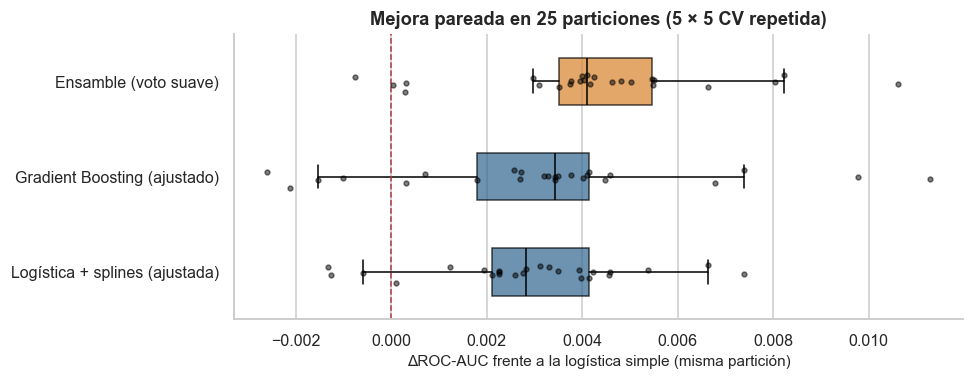

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
claves = [c for c in finalistas if c != "logistica"]
difs = [resultados_rep[c]["ROC-AUC"] - ref["ROC-AUC"] for c in claves]
partes = ax.boxplot(difs, vert=False, widths=0.5, patch_artist=True, showfliers=False, medianprops={"color": "black"})
for caja, c in zip(partes["boxes"], claves):
    caja.set_facecolor(eu.NARANJA if c == ELECCION else eu.AZUL)
    caja.set_alpha(0.7)
for i, d in enumerate(difs, start=1):
    ax.scatter(d, np.random.default_rng(0).normal(i, 0.05, len(d)), s=10, color="black", alpha=0.5, zorder=3)
ax.axvline(0, color=eu.ROJO, ls="--", lw=1)
ax.set_yticklabels([finalistas[c][0] for c in claves])
ax.set(xlabel="ΔROC-AUC frente a la logística simple (misma partición)",
       title="Mejora pareada en 25 particiones (5 × 5 CV repetida)")
eu.rejilla_x(ax)
fig.tight_layout()
eu.guardar_figura(fig, "fig23_eleccion_final")

**Hallazgos.** - Los tres finalistas superan a la logística simple en ≥ 84 % de las 25 particiones, así que todos cumplen la regla. El **ensamble** es el de mayor AUC (**0,8275**, +0,0042) y el más consistente: mejor en el **96 %** de las particiones (24/25). También tiene el mejor Brier y log-loss.
- Es una ganancia modesta pero sistemática. Su coste es asumible: 1,3 s de ajuste y milisegundos por predicción en la API.
- **Elegido: ensamble por voto suave.**

## 7. Calibración y umbral de decisión

Ambos se estudian con **predicciones fuera de pliegue** en train: cada paciente recibe la probabilidad de un modelo que no lo vio al entrenar. El test sigue sin tocarse.

### 7.1 Calibración
Lo que se pregunta es si, entre los pacientes con probabilidad ≈ 0,3, hay de verdad ≈ 30 % de diabéticos. Se compara el modelo tal cual con una recalibración isotónica (`CalibratedClassifierCV`), que solo se adopta si mejora el Brier.

In [12]:
estimador_elegido = finalistas[ELECCION][1]
proba_oof = cross_val_predict(md.construir_modelo(LINEA, estimador_elegido), X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]
proba_oof_iso = cross_val_predict(
    md.construir_modelo(LINEA, CalibratedClassifierCV(estimador_elegido, method="isotonic", cv=5)),
    X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

calibracion = pd.DataFrame({
    "sin recalibrar": md.metricas(y_train.values, proba_oof, 0.5),
    "isotónica": md.metricas(y_train.values, proba_oof_iso, 0.5),
}).loc[["ROC-AUC", "Brier", "Log-loss"]]
RECALIBRAR = calibracion.loc["Brier", "isotónica"] < calibracion.loc["Brier", "sin recalibrar"] - 0.001
print("¿Se adopta la recalibración isotónica?", "sí" if RECALIBRAR else "no (no mejora el Brier de forma apreciable)")
calibracion.style.format("{:.4f}")

¿Se adopta la recalibración isotónica? no (no mejora el Brier de forma apreciable)


,sin recalibrar,isotónica
ROC-AUC,0.8276,0.8265
Brier,0.1571,0.1576
Log-loss,0.4728,0.4777


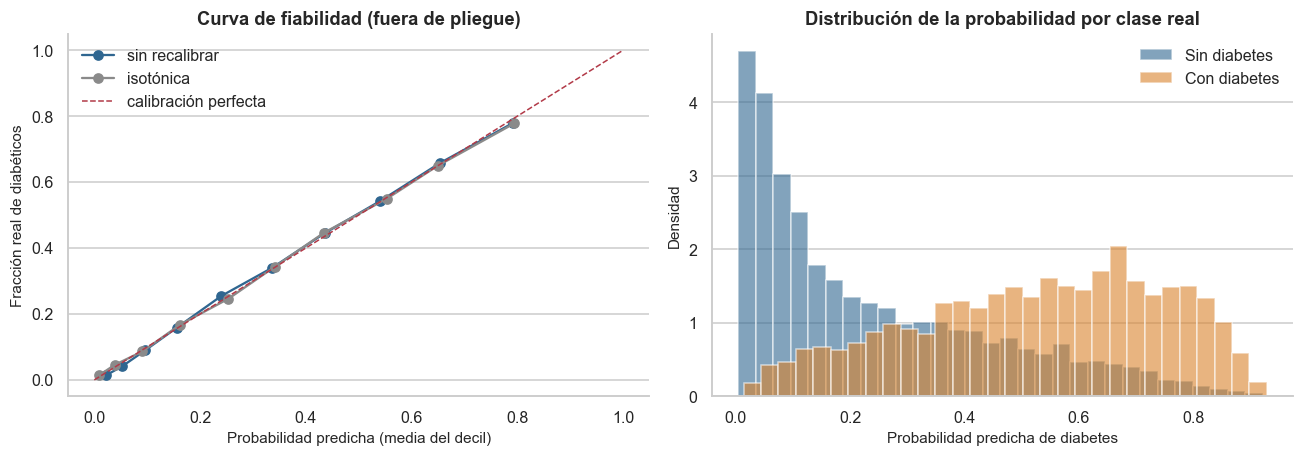

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
for proba, nombre, color in [(proba_oof, "sin recalibrar", eu.AZUL), (proba_oof_iso, "isotónica", eu.GRIS)]:
    frac, media = calibration_curve(y_train, proba, n_bins=10, strategy="quantile")
    ax.plot(media, frac, marker="o", label=nombre, color=color)
ax.plot([0, 1], [0, 1], ls="--", color=eu.ROJO, lw=1, label="calibración perfecta")
ax.set(xlabel="Probabilidad predicha (media del decil)", ylabel="Fracción real de diabéticos",
       title="Curva de fiabilidad (fuera de pliegue)")
ax.legend()
ax = axes[1]
for clase in (0, 1):
    ax.hist(proba_oof[y_train.values == clase], bins=30, alpha=0.6, density=True,
            color=eu.PALETA_DIABETES[clase], label=eu.ETIQUETAS_DIABETES[clase])
ax.set(xlabel="Probabilidad predicha de diabetes", ylabel="Densidad", title="Distribución de la probabilidad por clase real")
ax.legend()
fig.tight_layout()
eu.guardar_figura(fig, "fig24_calibracion")

**Hallazgos.** - Las probabilidades del ensamble ya están **bien calibradas**: la curva de fiabilidad sigue la diagonal en todos los deciles. La recalibración isotónica no mejora el Brier (0,1576 frente a 0,1571) y empeora el log-loss, porque escalona las probabilidades. **No se recalibra.**
- Las dos clases se separan bien, aunque con solapamiento en la zona 0,2–0,5. Ese solapamiento es el que fija el techo del AUC.
- Recordatorio: "bien calibradas" respecto a la **muestra remuestreada al 33 %**, no respecto a la prevalencia real (sección 10).

### 7.2 Umbral de decisión (`clase`)
El contrato devuelve, además de la probabilidad, una `clase`, y esta depende del umbral. El 0,5 por defecto no tiene nada de especial. Se comparan tres criterios sobre las probabilidades fuera de pliegue:
- **0,5**, el valor por defecto;
- **máximo F1**, que equilibra sensibilidad y VPP;
- **Youden**, que maximiza sensibilidad + especificidad − 1.

En un **cribado** el coste de un falso negativo (un diabético al que no se cita) es mayor que el de un falso positivo (una prueba de más). Por eso se prefiere un umbral por debajo de 0,5, siempre que no dispare los falsos positivos. **Criterio elegido: máximo F1**, porque es el que mantiene la sensibilidad alta sin hundir el VPP. Youden se muestra como contraste.

In [14]:
proba_umbral = proba_oof_iso if RECALIBRAR else proba_oof
rejilla = np.round(np.arange(0.05, 0.951, 0.01), 2)
curva = pd.DataFrame([md.metricas(y_train.values, proba_umbral, u) for u in rejilla], index=rejilla)
curva["Youden"] = curva["Sensibilidad"] + curva["Especificidad"] - 1

UMBRAL = float(curva["F1"].idxmax())
umbrales = {"0,5 (por defecto)": 0.5, "máximo F1 (elegido)": UMBRAL, "Youden": float(curva["Youden"].idxmax())}
tabla_umbral = pd.DataFrame({k: curva.loc[v, ["Sensibilidad", "Especificidad", "Precisión (VPP)", "F1", "Exactitud"]]
                             for k, v in umbrales.items()}).T
tabla_umbral.insert(0, "umbral", list(umbrales.values()))
tabla_umbral.style.format("{:.3f}")

,umbral,Sensibilidad,Especificidad,Precisión (VPP),F1,Exactitud
"0,5 (por defecto)",0.500,0.575,0.856,0.665,0.616,0.762
máximo F1 (elegido),0.350,0.773,0.729,0.587,0.668,0.744
Youden,0.350,0.773,0.729,0.587,0.668,0.744


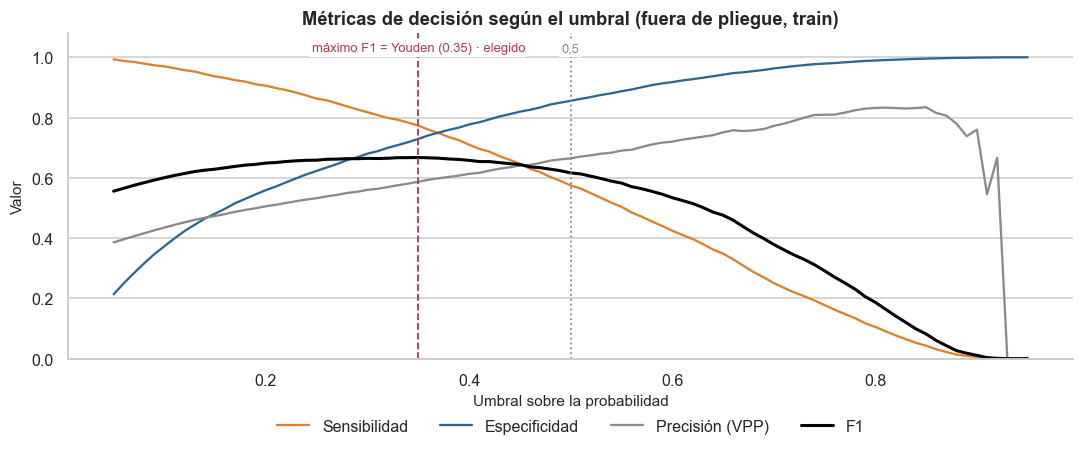

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.3))
for col, color in [("Sensibilidad", eu.NARANJA), ("Especificidad", eu.AZUL), ("Precisión (VPP)", eu.GRIS), ("F1", "black")]:
    ax.plot(curva.index, curva[col], label=col, color=color, lw=2 if col == "F1" else 1.5)
# Umbrales que coinciden se anotan juntos para que las etiquetas no se solapen
for u in sorted(set(umbrales.values())):
    nombres = [n.split(" (")[0] for n, v in umbrales.items() if v == u]
    elegido = u == UMBRAL
    ax.axvline(u, ls="--" if elegido else ":", color=eu.ROJO if elegido else eu.GRIS, lw=1.2)
    etiqueta = " = ".join(nombres) + (f" ({u:.2f}) · elegido" if elegido else "")
    ax.text(u, 1.02, etiqueta, ha="center", fontsize=8.5, color=eu.ROJO if elegido else eu.GRIS,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})
ax.set(xlabel="Umbral sobre la probabilidad", ylabel="Valor", ylim=(0, 1.08),
       title="Métricas de decisión según el umbral (fuera de pliegue, train)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4)
fig.tight_layout()
eu.guardar_figura(fig, "fig25_umbral")

**Hallazgos.** - Con el umbral por defecto (0,5) el modelo **solo detecta el 58 % de los diabéticos**, inaceptable para un cribado.
- El máximo F1 cae en **0,35**, y Youden coincide con él. Ahí la sensibilidad sube a **0,77** (+20 puntos) y la especificidad baja a 0,73 (−13 puntos). F1 pasa de 0,62 a 0,67. Que dos criterios distintos coincidan da robustez a la elección.
- La curva de F1 es plana entre 0,25 y 0,40. Si el consorcio quisiera más sensibilidad (p. ej. 0,85), bastaría con bajar el umbral a ≈ 0,27 sin cambiar el modelo (especificidad 0,65).

La configuración resultante (modelo, hiperparámetros y umbral) se fija en `md.CONFIG_FINAL`. La siguiente celda **comprueba** que lo que hay en el código coincide con lo que acaban de decidir las secciones 5–7, para que notebook y artefacto no puedan desincronizarse.

In [16]:
cfg = md.CONFIG_FINAL[LINEA]
decidido = {"estimador": ELECCION, "umbral": UMBRAL, "recalibrar": bool(RECALIBRAR)}
en_codigo = {"estimador": cfg["estimador"], "umbral": cfg["umbral"], "recalibrar": False}
if ELECCION in ("logistica_splines", "ensamble"):
    decidido["params_logistica"], en_codigo["params_logistica"] = params_log, cfg["params_logistica"]
if ELECCION in ("gradient_boosting", "ensamble"):
    decidido["params_boosting"], en_codigo["params_boosting"] = params_gb, cfg["params_boosting"]
print(json.dumps(decidido, indent=2, ensure_ascii=False))
assert decidido == en_codigo, f"Actualizar md.CONFIG_FINAL:\n{decidido}"
print("✔ md.CONFIG_FINAL coincide con la configuración decidida en este notebook.")

{
  "estimador": "ensamble",
  "umbral": 0.35,
  "recalibrar": false,
  "params_logistica": {
    "C": 1,
    "nodos_imc": 4,
    "nodos_resto": 4
  },
  "params_boosting": {
    "l2_regularization": 7.076,
    "learning_rate": 0.0213,
    "max_iter": 485,
    "max_leaf_nodes": 6,
    "min_samples_leaf": 122
  }
}
✔ md.CONFIG_FINAL coincide con la configuración decidida en este notebook.


## 8. Evaluación final en test (una sola vez)

El modelo final (`md.construir_final`) se ajusta con todo train y se evalúa **una única vez** sobre los 2 550 pacientes de test. Los intervalos de confianza al 95 % salen de un bootstrap de 1 000 remuestreos de pacientes. Se compara con el `Dummy` y con lo que anticipaba la validación cruzada.

In [17]:
modelo_final = md.construir_final(LINEA).fit(X_train, y_train)
proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = modelo_final.predict(X_test)

dummy = md.construir_modelo(LINEA, DummyClassifier(strategy="prior")).fit(X_train, y_train)
proba_dummy = dummy.predict_proba(X_test)[:, 1]

ic_test = md.metricas_con_ic(y_test, proba_test, UMBRAL)
esperado_cv = pd.Series(md.metricas(y_train.values, proba_oof, UMBRAL))
evaluacion = ic_test.assign(**{"CV (fuera de pliegue)": esperado_cv,
                               "Dummy en test": pd.Series(md.metricas(y_test.values, proba_dummy, UMBRAL))})
evaluacion.style.format("{:.3f}")

,valor,IC inf.,IC sup.,CV (fuera de pliegue),Dummy en test
ROC-AUC,0.826,0.809,0.842,0.828,0.500
PR-AUC,0.683,0.646,0.718,0.677,0.333
Brier,0.158,0.150,0.166,0.157,0.222
Log-loss,0.474,0.454,0.493,0.473,0.636
Sensibilidad,0.759,0.727,0.789,0.773,0.000
Especificidad,0.726,0.705,0.746,0.729,1.000
Precisión (VPP),0.580,0.549,0.608,0.587,0.000
F1,0.658,0.632,0.683,0.668,0.000
Exactitud,0.737,0.720,0.753,0.744,0.667


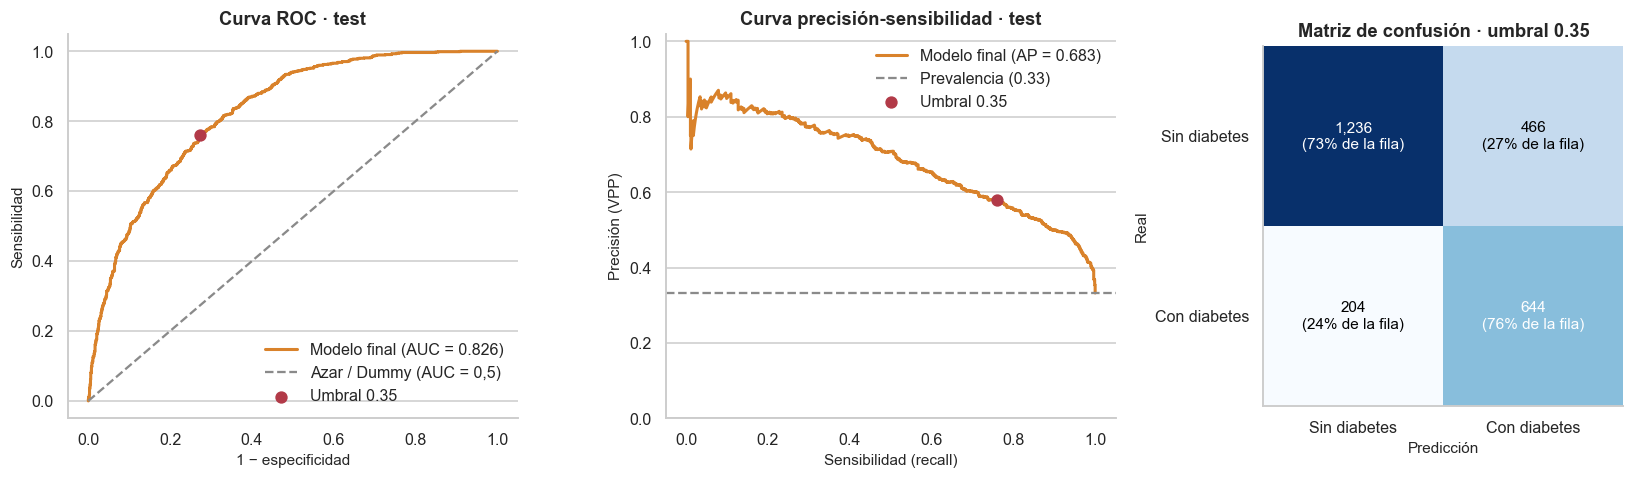

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1, 0.8]})
fpr, tpr, _ = roc_curve(y_test, proba_test)
ax = axes[0]
ax.plot(fpr, tpr, color=eu.NARANJA, lw=2, label=f"Modelo final (AUC = {ic_test.loc['ROC-AUC', 'valor']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=eu.GRIS, label="Azar / Dummy (AUC = 0,5)")
sens, esp = ic_test.loc["Sensibilidad", "valor"], ic_test.loc["Especificidad", "valor"]
ax.scatter(1 - esp, sens, color=eu.ROJO, zorder=3, s=50, label=f"Umbral {UMBRAL:.2f}")
ax.set(xlabel="1 − especificidad", ylabel="Sensibilidad", title="Curva ROC · test")
ax.legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y_test, proba_test)
ax = axes[1]
ax.plot(rec, prec, color=eu.NARANJA, lw=2, label=f"Modelo final (AP = {ic_test.loc['PR-AUC', 'valor']:.3f})")
ax.axhline(y_test.mean(), ls="--", color=eu.GRIS, label=f"Prevalencia ({y_test.mean():.2f})")
ax.scatter(sens, ic_test.loc["Precisión (VPP)", "valor"], color=eu.ROJO, zorder=3, s=50, label=f"Umbral {UMBRAL:.2f}")
ax.set(xlabel="Sensibilidad (recall)", ylabel="Precisión (VPP)", title="Curva precisión-sensibilidad · test", ylim=(0, 1.02))
ax.legend(loc="upper right")

ax = axes[2]
cm = confusion_matrix(y_test, pred_test)
ax.imshow(cm, cmap=eu.CMAP_SECUENCIAL)
etiquetas = ["Sin diabetes", "Con diabetes"]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.0%} de la fila)", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=10)
ax.set_xticks([0, 1], etiquetas)
ax.set_yticks([0, 1], etiquetas)
ax.set(xlabel="Predicción", ylabel="Real", title=f"Matriz de confusión · umbral {UMBRAL:.2f}")
ax.grid(False)
fig.tight_layout()
eu.guardar_figura(fig, "fig26_evaluacion_test")

**Hallazgos.** - **ROC-AUC en test 0,826 [0,809–0,842]**, prácticamente igual a la CV (0,828). Brier, log-loss, sensibilidad y especificidad también caen dentro de sus IC. **No hay sobreajuste** a la validación, ni por la búsqueda de hiperparámetros ni por la elección del umbral.
- Frente al Dummy: +0,33 de AUC y Brier de 0,158 frente a 0,222.
- En la práctica, de 848 diabéticos de test el modelo **cita a 644 (76 %)**. Por el camino genera 466 falsos positivos sobre 1 702 sanos (27 %), un coste razonable si la prueba de confirmación es barata (glucemia o HbA1c). Uno de cada 1,7 citados es diabético, frente a uno de cada 3 citando al azar.

## 9. Interpretación: ¿qué ha aprendido el modelo?

- **Importancia por permutación sobre test**, con ROC-AUC y 20 repeticiones. Como el modelo recibe columnas crudas, se permuta cada **variable original** completa. Su efecto incluye también el de las derivadas que se calculan a partir de ella (p. ej. `imc` arrastra `imc_categoria` y `falta_imc`).
- **Dependencia parcial**: la probabilidad media predicha al fijar una variable en cada uno de sus valores para todos los pacientes de test. Muestra la **forma** del efecto que ha aprendido el modelo. No es un efecto causal.

,caída de ROC-AUC,de
salud_general,0.0560,0.0052
imc,0.0319,0.0033
grupo_edad,0.0262,0.0029
presion_alta,0.0147,0.0023
colesterol_alto,0.0110,0.0018
nivel_ingresos,0.0050,0.0010
chequeo_colesterol_5a,0.0040,0.0010
sexo,0.0029,0.0008


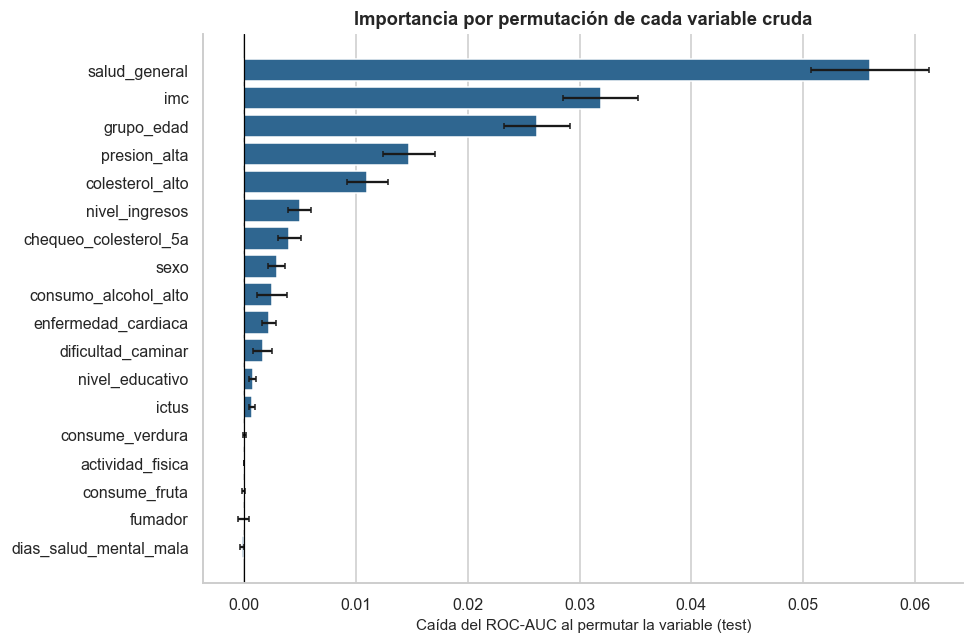

In [19]:
perm = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=20,
                              random_state=pp.SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"caída de ROC-AUC": perm.importances_mean, "de": perm.importances_std},
                           index=X_test.columns).sort_values("caída de ROC-AUC")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importancia.index, importancia["caída de ROC-AUC"], xerr=importancia["de"], color=eu.AZUL, capsize=2)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Caída del ROC-AUC al permutar la variable (test)", title="Importancia por permutación de cada variable cruda")
eu.rejilla_x(ax)
fig.tight_layout()
eu.guardar_figura(fig, "fig27_importancia_permutacion")
importancia.sort_values("caída de ROC-AUC", ascending=False).head(8).style.format("{:.4f}")

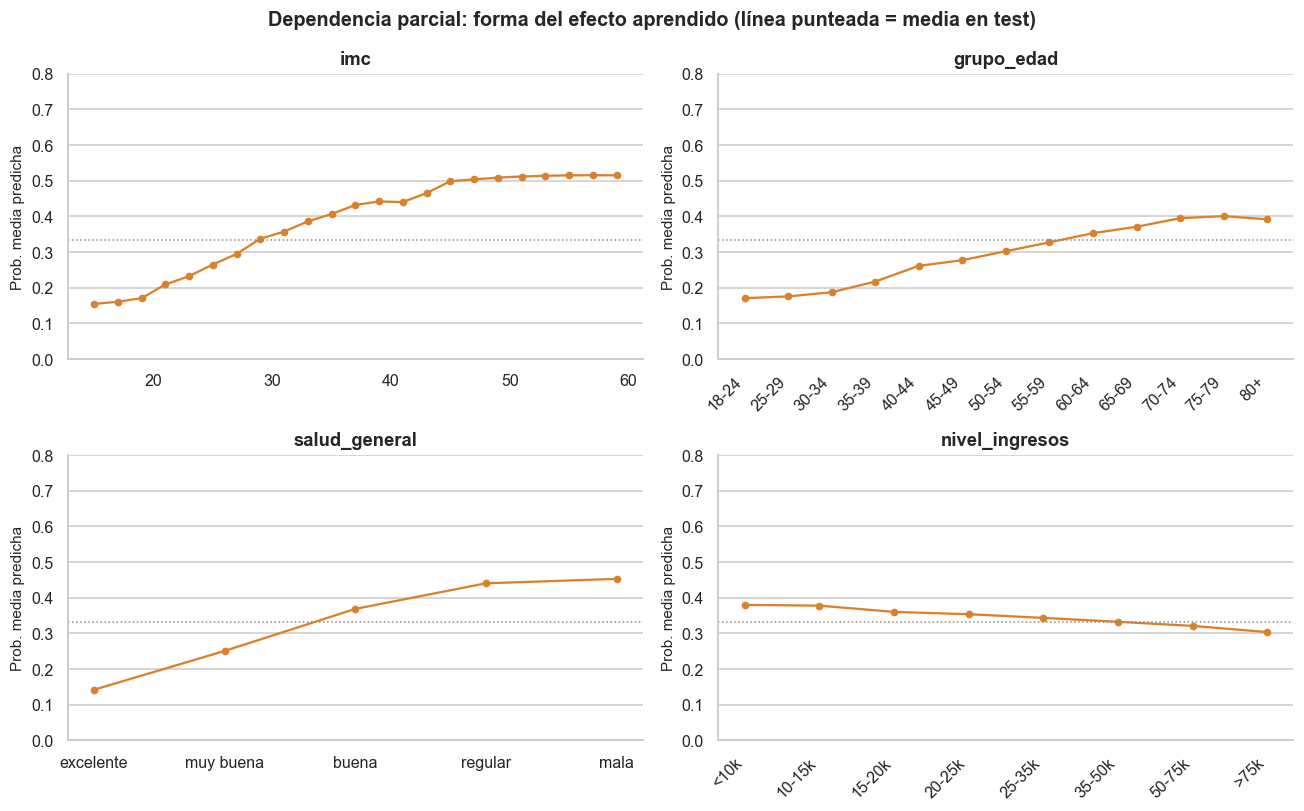

In [20]:
variables_pd = {
    "imc": list(range(15, 61, 2)),
    "grupo_edad": list(pp.ORDEN_EDAD),
    "salud_general": list(pp.ORDEN_SALUD_GENERAL),
    "nivel_ingresos": list(pp.ORDEN_INGRESOS),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (col, valores) in zip(axes.flat, variables_pd.items()):
    dp = md.dependencia_parcial(modelo_final, X_test, col, valores)
    x = np.arange(len(dp)) if col != "imc" else dp.index
    ax.plot(x, dp.values, marker="o", color=eu.NARANJA, ms=4)
    if col != "imc":
        ax.set_xticks(x, dp.index, rotation=45 if col in ("grupo_edad", "nivel_ingresos") else 0, ha="right" if col != "salud_general" else "center")
    ax.axhline(proba_test.mean(), ls=":", color=eu.GRIS, lw=1)
    ax.set(title=col, ylabel="Prob. media predicha", ylim=(0, 0.8))
fig.suptitle("Dependencia parcial: forma del efecto aprendido (línea punteada = media en test)")
fig.tight_layout()
eu.guardar_figura(fig, "fig28_dependencia_parcial")

**Hallazgos.** - **Importancia**: salud percibida (−0,056 de AUC al permutarla), IMC (−0,032), edad (−0,026), hipertensión (−0,015) y colesterol (−0,011). El resto aporta < 0,005 cada una. Es el mismo ranking de asociación del EDA (fig12): el modelo no se apoya en artefactos.
- **Formas del efecto**, todas monótonas y clínicamente plausibles:
  - **IMC**: el riesgo sube de forma casi lineal desde ≈ 0,15 (IMC 18) hasta ≈ 0,50 (IMC 45) y **se aplana** a partir de ahí. Ese techo es justo lo que la logística simple no podía capturar y los splines sí.
  - **Edad**: gradiente continuo hasta los 70–79 años y ligera caída a partir de los 80. Cuadra con el sesgo de supervivencia que se vio en el EDA.
  - **Salud general**: el efecto más fuerte, de 0,14 (excelente) a 0,45 (mala).
  - **Ingresos**: gradiente socioeconómico suave (0,38 → 0,30).
- Son asociaciones, no causas. Por ejemplo, la mala salud percibida es en parte *consecuencia* de la diabetes.

## 10. Lo que se probó y se descartó · limitaciones

| Se probó | Resultado | Decisión |
|---|---|---|
| `dias_salud_fisica_mala` como predictor (clasificación) | ΔROC-AUC = 0,0000 | Descartado (sección 2) |
| `diabetes` como predictor (regresión) | ΔMAE = −0,002 días (peor) | Descartado (sección 2) |
| Logística con 4 indicadores clínicos | ROC-AUC 0,780 | Solo como referencia |
| KNN (k = 50) | 0,816; peor que la logística en 5/5 pliegues | Descartado |
| Random Forest | 0,820; peor en 4/5 pliegues y 10× más lento | Descartado |
| Logística o boosting por separado | 0,826–0,827; el ensamble gana en el 96 % de particiones | Integrados en el ensamble |
| Recalibración isotónica | Brier 0,1576 frente a 0,1571; log-loss peor | No se aplica |
| Umbral 0,5 | Sensibilidad 0,58 | Sustituido por 0,35 |

**Limitaciones**
- **Probabilidades no poblacionales.** El entrenamiento usa una muestra remuestreada al 33 % de diabéticos. Si el consorcio quisiera probabilidades reales, habría que corregir el *prior*: multiplicar las *odds* por (π_real/(1−π_real)) / (0,33/0,67). Los umbrales tampoco se trasladan sin reajustarlos.
- **Techo de información.** Los cuatro tipos de modelo se quedan en ROC-AUC ≈ 0,82–0,83. Todo indica que el límite está en los datos (encuesta autorreportada, sin analítica), no en el algoritmo.
- **Uso.** Es una herramienta de **priorización** para citar a pruebas, no de diagnóstico.

## 11. Comprobaciones finales sobre el modelo que se va a servir

Cada comprobación es un `assert`: si alguna falla, el notebook se detiene.

In [21]:
comprobaciones = []
def comprobar(descripcion, condicion):
    assert condicion, descripcion
    comprobaciones.append(descripcion)

comprobar("1. Train y test son disjuntos (ningún paciente de test se usó para seleccionar)",
          not set(X_train.index) & set(X_test.index))
comprobar("2. El modelo pide exactamente las 18 columnas crudas, sin PII, id ni objetivos",
          list(modelo_final.feature_names_in_) == COLUMNAS)
comprobar("3. ROC-AUC en test supera al Dummy en más de 0,25 y su IC 95 % no incluye 0,5",
          ic_test.loc["ROC-AUC", "valor"] > 0.75 and ic_test.loc["ROC-AUC", "IC inf."] > 0.5)
cv_auc = resultados_rep[ELECCION]["ROC-AUC"]
comprobar("4. ROC-AUC en test dentro de la media de CV ± 2 de (sin sobreajuste a la validación)",
          abs(ic_test.loc["ROC-AUC", "valor"] - cv_auc.mean()) <= 2 * cv_auc.std())
comprobar("5. Todas las probabilidades están en [0, 1]", ((proba_test >= 0) & (proba_test <= 1)).all())
comprobar("6. `predict` aplica el umbral elegido: clase = 1 ⇔ probabilidad ≥ umbral",
          (pred_test == (proba_test >= UMBRAL).astype(int)).all())

dificil = X_test.iloc[:3].copy()
dificil.iloc[0] = np.nan                                       # paciente sin ningún dato
dificil.iloc[1, :] = X_test.iloc[1].values
dificil.loc[dificil.index[1], ["fumador", "actividad_fisica", "salud_general", "sexo"]] = ["Sí", "YES", " Muy Buena ", "MUJER"]
dificil.loc[dificil.index[2], ["imc", "grupo_edad"]] = [250, "edad desconocida"]   # fuera de rango / no reconocido
p_dificil = modelo_final.predict_proba(dificil)[:, 1]
comprobar("7. Instancias con nulos, codificaciones no vistas y valores imposibles reciben predicción válida",
          len(p_dificil) == 3 and np.isfinite(p_dificil).all())
comprobar("8. Reproducible: reajustar con la misma configuración da exactamente las mismas probabilidades",
          np.allclose(md.construir_final(LINEA).fit(X_train, y_train).predict_proba(X_test)[:, 1], proba_test))
comprobar("9. Una predicción por instancia (el contrato lo exige)",
          len(modelo_final.predict(X_test)) == len(X_test))
comprobar("10. El objeto que se sirve referencia `preprocesamiento`/`modelado` como módulos de primer nivel",
          modelo_final.named_steps["pre"].named_steps["preparar"].func.__module__ == "preprocesamiento")

print("\n".join(f"✔ {c}" for c in comprobaciones))

✔ 1. Train y test son disjuntos (ningún paciente de test se usó para seleccionar)
✔ 2. El modelo pide exactamente las 18 columnas crudas, sin PII, id ni objetivos
✔ 3. ROC-AUC en test supera al Dummy en más de 0,25 y su IC 95 % no incluye 0,5
✔ 4. ROC-AUC en test dentro de la media de CV ± 2 de (sin sobreajuste a la validación)
✔ 5. Todas las probabilidades están en [0, 1]
✔ 6. `predict` aplica el umbral elegido: clase = 1 ⇔ probabilidad ≥ umbral
✔ 7. Instancias con nulos, codificaciones no vistas y valores imposibles reciben predicción válida
✔ 8. Reproducible: reajustar con la misma configuración da exactamente las mismas probabilidades
✔ 9. Una predicción por instancia (el contrato lo exige)
✔ 10. El objeto que se sirve referencia `preprocesamiento`/`modelado` como módulos de primer nivel


In [22]:
# Métricas para el README y para los metadatos del artefacto (src/entrenar.py las adjunta)
salida = {
    "linea": LINEA,
    "modelo": finalistas[ELECCION][0],
    "config": md.CONFIG_FINAL[LINEA],
    "columnas_entrada": COLUMNAS,
    "cv_repetida_5x5": resultados_rep[ELECCION][["ROC-AUC", "PR-AUC", "Brier", "Log-loss"]].mean().round(4).to_dict(),
    "test": {m: {k: round(float(v), 4) for k, v in fila.items()} for m, fila in ic_test.iterrows()},
    "objetivo_cruzado": objetivo_cruzado.reset_index().round(4).to_dict(orient="records"),
}
ruta = pp.RUTA_PROYECTO / "reports" / "metricas_clasificacion.json"
ruta.write_text(json.dumps(salida, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Guardado {ruta.relative_to(pp.RUTA_PROYECTO)}")

Guardado reports\metricas_clasificacion.json


## 12. Siguiente paso: artefacto y API

Este notebook decide y valida. El **artefacto que sirve la API** lo genera un script reproducible que reajusta `md.CONFIG_FINAL` con **todo** el conjunto de desarrollo (train + test, 12 750 pacientes). Con la configuración ya cerrada, más datos solo pueden ayudar, y las métricas de arriba siguen siendo la estimación honesta de su rendimiento.

```bash
python src/entrenar.py clasificacion         # → artifacts/proy_modelo_clasificacion.joblib (+ .json)
uvicorn src.servicio:app --port 8000         # API del contrato común
python -m pytest tests -q                    # pruebas del servicio
```